# Passo 1.2 — Neutralidade da moeda no Brasil

**Objetivo.** O argumento neofisheriano do ALR (seguindo Cochrane, 2023) tem DUAS
premissas encadeadas:

1. **No longo prazo, π = i − r** (Fisher)
2. **r é independente de i no longo prazo** (neutralidade da moeda)

Se (2) for violada — ou seja, se r responde a i no longo prazo — então reduzir i
reduz r também, e a inflação π = i − r pode **subir, cair ou não se mover**,
dependendo de qual efeito domina. A **tese ALR cai**: cortar Selic não leva
mecanicamente à desinflação.

**O que o Passo 1.1 deixou em aberto:**

- OLS: β = +0,323 (direção ALR, com cointegração)
- Johansen: β = −0,459 (direção convencional)
- A discordância sugere que a identificação causal importa

**Como o Passo 1.2 resolve isso.** Um VAR/VECM nas variáveis (π, i) permite:

- **Decomposição de variância**: quanto da variância de π no longo prazo é explicada
  por choques de i? (Se baixa, política monetária é fraca → consistente com ALR.)
- **Impulse response functions (IRF)**: o que acontece com π e com r = i − π depois
  de um choque em i? (Se r sobe muito e π pouco, não há neutralidade.)
- **Testes de Granger-causalidade**: i Granger-causa π? Se sim, mecanismo clássico vale.

**Nota técnica.** Não usamos (π, i, r) juntos no VAR porque r = i − π é identidade
linear (matriz singular). Trabalhamos com (π, i) e inferimos r pela identidade de
Fisher aplicada às trajetórias de resposta.


## 1. Setup e dados

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, select_order, select_coint_rank
from statsmodels.tsa.stattools import grangercausalitytests

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# Mesmo carregamento do Passo 1.1 (com fix da data)
CACHE_DIR = Path("cache_dados")
if not CACHE_DIR.exists():
    CACHE_DIR = Path("../cache_dados")
assert CACHE_DIR.exists(), f"Não achei cache_dados em {CACHE_DIR.resolve()}"

Path("figs").mkdir(exist_ok=True)

def load_sgs(code):
    f = CACHE_DIR / f"sgs_{code}.csv"
    df_raw = pd.read_csv(f)
    date_col = [c for c in df_raw.columns if c.lower() in ("data", "date")][0]
    val_col  = [c for c in df_raw.columns if c.lower() in ("valor", "value")][0]
    df_raw[date_col] = pd.to_datetime(df_raw[date_col], errors="coerce")
    df_raw = df_raw.dropna(subset=[date_col]).sort_values(date_col).set_index(date_col)
    s = pd.to_numeric(df_raw[val_col], errors="coerce").dropna()
    s.name = f"sgs_{code}"
    return s

ipca_mensal = load_sgs(433)
try:
    selic = load_sgs(432)
except Exception:
    selic = load_sgs(4189)

# IPCA 12m + Selic trimestral (normaliza para fim de mês)
ipca = ipca_mensal.copy()
ipca.index = ipca.index + pd.offsets.MonthEnd(0)
_frac = ipca / 100
ipca_12m_mensal = ((1 + _frac).rolling(12).apply(np.prod, raw=True) - 1) * 100
pi_trim = ipca_12m_mensal.resample("QE").last()
pi_trim.name = "pi"

sel = selic.copy()
sel.index = sel.index + pd.offsets.MonthEnd(0)
i_trim = sel.resample("QE").mean()
i_trim.name = "i"

df = pd.concat([pi_trim, i_trim], axis=1).dropna()
df["r"] = df["i"] - df["pi"]  # juro real ex-post

print(f"Amostra: {df.index.min().date()} a {df.index.max().date()}  ({len(df)} trimestres)")
print(f"Média π: {df['pi'].mean():.3f}%  |  Média i: {df['i'].mean():.3f}%  |  Média r: {df['r'].mean():.3f}%")
print()
print("Primeiros/últimos 3 trimestres:")
print(pd.concat([df.head(3), df.tail(3)]).round(3))


Amostra: 2002-12-31 a 2026-06-30  (95 trimestres)
Média π: 6.079%  |  Média i: 11.804%  |  Média r: 5.725%

Primeiros/últimos 3 trimestres:
               pi      i      r
data                           
2002-12-31 12.530 21.413  8.883
2003-03-31 16.573 25.822  9.250
2003-06-30 16.570 26.440  9.870
2025-12-31  4.264 15.000 10.736
2026-03-31  4.143 14.964 10.821
2026-06-30  4.392 14.648 10.256


## 2. Seleção de ordem do VAR

Usa critérios de informação (AIC, BIC, HQIC) pra escolher o número de lags.


In [2]:
# VAR(π, i) — não inclui r porque r = i - π é identidade linear (singular)
Y = df[["pi", "i"]]

sel_order_lvl = select_order(Y, maxlags=8, deterministic="ci")
print("Seleção de ordem (VAR em níveis, com constante na cointegração):")
print(sel_order_lvl.summary())
print()
k_ar = sel_order_lvl.aic
if k_ar == 0:
    k_ar = 1  # VAR precisa de pelo menos 1 lag
print(f"→ Número de lags escolhido (AIC): k = {k_ar}")


Seleção de ordem (VAR em níveis, com constante na cointegração):
 VECM Order Selection (* highlights the minimums)
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0     -0.5862     -0.3579      0.5565     -0.4943
1      -1.460      -1.118      0.2323      -1.322
2      -1.707     -1.251*      0.1816      -1.524
3      -1.770      -1.199      0.1708      -1.540
4     -1.834*      -1.149     0.1603*     -1.559*
5      -1.780     -0.9808      0.1696      -1.458
6      -1.704     -0.7907      0.1836      -1.336
7      -1.644     -0.6168      0.1956      -1.231
8      -1.742     -0.6009      0.1781      -1.283
-------------------------------------------------

→ Número de lags escolhido (AIC): k = 4


## 3. Rank de cointegração (Johansen trivariado)

Com 3 variáveis, podemos ter 0, 1 ou 2 vetores de cointegração.
Cada vetor é uma relação de equilíbrio independente.


In [3]:
# Lags para o Johansen (geralmente k_ar-1 do VAR)
k_diff = max(k_ar - 1, 1)

rank_test = select_coint_rank(Y, det_order=0, k_ar_diff=k_diff,
                               method="trace", signif=0.05)
print(f"Teste Johansen Trace (lag diff = {k_diff}):")
print(rank_test.summary())
print()
r_coint = rank_test.rank
print(f"→ Rank de cointegração estimado: r = {r_coint}")
print()
if r_coint == 0:
    print("  Nenhum vetor: π e i não têm relação de equilíbrio.")
elif r_coint == 1:
    print("  Um vetor: há UMA relação de equilíbrio entre π e i.")
    print("  O coeficiente do vetor dá a direção (positivo = ALR, negativo = convencional).")
elif r_coint == 2:
    print("  Dois vetores: ambas as séries são estacionárias em nível.")


Teste Johansen Trace (lag diff = 3):
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   2          36.43          15.49
  1   2          6.826          3.841
-------------------------------------

→ Rank de cointegração estimado: r = 2

  Dois vetores: ambas as séries são estacionárias em nível.


## 4. Estima VECM e inspeciona o vetor de cointegração

Se há cointegração, o VECM dá o vetor de equilíbrio β e a matriz de ajuste α.

**Teste-chave para neutralidade.** Se Fisher vale literalmente, o vetor β deveria
ser (aproximadamente) `[1, -1, +1]` em (π, i, r), ou seja: π - i + r = 0 → π = i - r.


In [4]:
if r_coint == 1:
    vecm = VECM(Y, k_ar_diff=k_diff, coint_rank=1, deterministic="ci").fit()

    print("Vetor β (relação de cointegração normalizada):")
    beta_mat = pd.DataFrame(vecm.beta, index=["pi", "i"], columns=["vec_1"])
    print(beta_mat.round(3))
    print()
    # Normaliza para pi = 1
    beta_i_lp = -vecm.beta[1, 0] / vecm.beta[0, 0]
    print(f"Relação de longo prazo: π = {beta_i_lp:+.3f} · i + const")
    print(f"Sinal: {'POSITIVO (direção ALR)' if beta_i_lp > 0 else 'NEGATIVO (direção convencional)'}")
    print()
    print("Matriz α (velocidades de ajustamento):")
    alpha_mat = pd.DataFrame(vecm.alpha, index=["pi", "i"], columns=["vec_1"])
    print(alpha_mat.round(3))
    print()
    print("Interpretação de α:")
    print("  α_π < 0: π retorna ao equilíbrio (ajusta ao desvio).")
    print("  α_i ≈ 0: i é fracamente exógeno (BC não ajusta a Selic ao desvio).")
    print("  α_i < 0: BC ativamente usa Selic para corrigir desvio (regra de Taylor).")
else:
    print(f"Rank = {r_coint}: VECM com 1 vetor não se aplica.")
    print("Vamos para VAR em diferenças/níveis para IRF.")


Rank = 2: VECM com 1 vetor não se aplica.
Vamos para VAR em diferenças/níveis para IRF.


## 5. Testes de Granger-causalidade bidirecionais

- **i → π**: a Selic Granger-causa a inflação? (Se sim, mecanismo clássico vale.)
- **π → i**: a inflação Granger-causa a Selic? (Se sim, BC reage à inflação — regra de Taylor.)

Se **só π → i** é significativo, a Selic REAGE à inflação mas não a CAUSA.
Esse é o resultado mais danoso para a política monetária convencional.


In [5]:
maxlag = max(k_ar, 4)

print("Granger-causalidade: i → π (H0: i NÃO causa π)")
print("-" * 60)
import io, contextlib
_buf = io.StringIO()
with contextlib.redirect_stdout(_buf):
    gc_i_pi = grangercausalitytests(df[["pi", "i"]], maxlag=maxlag)
p_i_pi = {}
for lag, res in gc_i_pi.items():
    p_f = res[0]["ssr_ftest"][1]
    p_i_pi[lag] = p_f
    v = "REJEITA (i causa π)" if p_f < 0.05 else "não rejeita"
    print(f"  lag {lag}: F p-valor = {p_f:.3f}   → {v}")

print()
print("Granger-causalidade: π → i (H0: π NÃO causa i)")
print("-" * 60)
with contextlib.redirect_stdout(_buf):
    gc_pi_i = grangercausalitytests(df[["i", "pi"]], maxlag=maxlag)
p_pi_i = {}
for lag, res in gc_pi_i.items():
    p_f = res[0]["ssr_ftest"][1]
    p_pi_i[lag] = p_f
    v = "REJEITA (π causa i)" if p_f < 0.05 else "não rejeita"
    print(f"  lag {lag}: F p-valor = {p_f:.3f}   → {v}")

print()
p_min_i_pi = min(p_i_pi.values())
p_min_pi_i = min(p_pi_i.values())
print(f"Menor p-valor i → π: {p_min_i_pi:.3f}  "
      f"({'SIGNIFICATIVO' if p_min_i_pi < 0.05 else 'não significativo'})")
print(f"Menor p-valor π → i: {p_min_pi_i:.3f}  "
      f"({'SIGNIFICATIVO' if p_min_pi_i < 0.05 else 'não significativo'})")
print()
if p_min_i_pi < 0.05 and p_min_pi_i < 0.05:
    print("→ Causalidade BIDIRECIONAL — BC reage e Selic afeta inflação.")
elif p_min_pi_i < 0.05 and p_min_i_pi >= 0.05:
    print("→ Só π → i significativo: BC REAGE à inflação, mas Selic NÃO move inflação.")
    print("  Este é o cenário que REFORÇA o argumento do ALR.")
elif p_min_i_pi < 0.05 and p_min_pi_i >= 0.05:
    print("→ Só i → π significativo: Selic move inflação, BC não reage (incomum).")
else:
    print("→ Nenhuma causalidade significativa.")


Granger-causalidade: i → π (H0: i NÃO causa π)
------------------------------------------------------------
  lag 1: F p-valor = 0.025   → REJEITA (i causa π)
  lag 2: F p-valor = 0.002   → REJEITA (i causa π)
  lag 3: F p-valor = 0.000   → REJEITA (i causa π)
  lag 4: F p-valor = 0.000   → REJEITA (i causa π)

Granger-causalidade: π → i (H0: π NÃO causa i)
------------------------------------------------------------
  lag 1: F p-valor = 0.001   → REJEITA (π causa i)
  lag 2: F p-valor = 0.669   → não rejeita
  lag 3: F p-valor = 0.176   → não rejeita
  lag 4: F p-valor = 0.041   → REJEITA (π causa i)

Menor p-valor i → π: 0.000  (SIGNIFICATIVO)
Menor p-valor π → i: 0.001  (SIGNIFICATIVO)

→ Causalidade BIDIRECIONAL — BC reage e Selic afeta inflação.


## 6. Impulse Response Functions (IRF) — choque em i → r e π

Visualmente: o que acontece com r e π quando i sobe 1 ponto percentual?

**Predição ALR (neofisheriana):**
- Choque em i → **r não muda no longo prazo** (fica em torno do neutro)
- Choque em i → π **sobe** no longo prazo (porque π = i − r)

**Predição convencional:**
- Choque em i → r **sobe** (porque juro real = juro nominal − inflação, e π não reage logo)
- Choque em i → π **cai** (porque juro real alto desaquece a economia)


VAR estimado com 4 lags

IRF — resposta a choque de 1 d.p. em i (primeiros 8 trimestres):
      pi     i  r_implicito
0  0.000 1.000        1.000
1  0.585 2.020        1.435
2  0.756 2.571        1.816
3  0.277 2.632        2.354
4 -0.209 2.292        2.501
5 -0.605 1.728        2.333
6 -0.897 1.163        2.059
7 -0.932 0.720        1.652

Resposta acumulada em 20 trimestres:
  π:  +0.016  (SOBE (direção ALR))
  r:  +0.131  (pouco afetado (ALR OK))

Interpretação neofisheriana:
  Choque em i → se π sobe tanto quanto i, r ≈ 0 (Fisher puro).
  Se π sobe pouco e r muito → juro real responde a juro nominal → neutralidade falha.


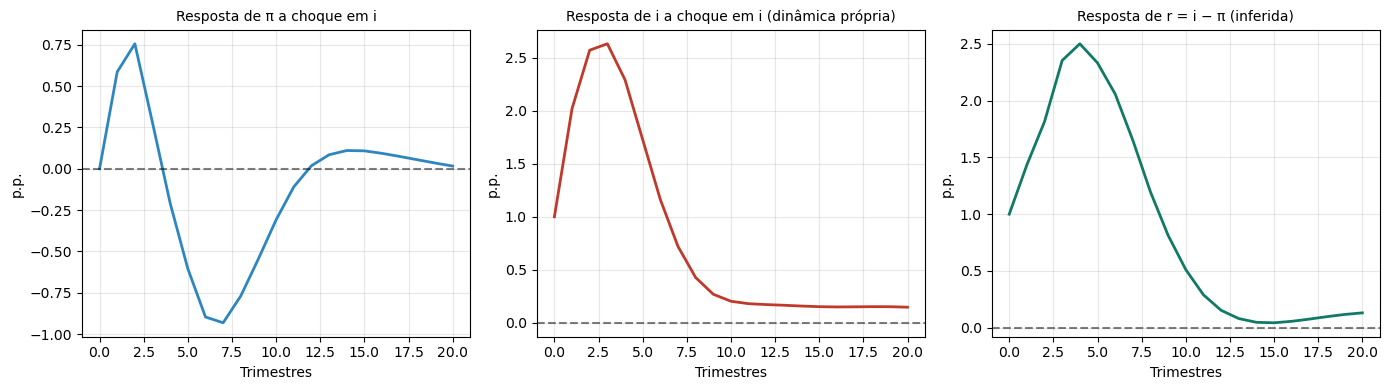

Figura salva em figs/fig_irf_neutralidade.png


In [6]:
# VAR(π, i) em níveis
var_mod = VAR(Y)
var_res = var_mod.fit(maxlags=k_ar, ic="aic")
print(f"VAR estimado com {var_res.k_ar} lags")
print()

# IRF: choque em i → π e i; depois INFERIMOS r pela identidade r = i - π
irf = var_res.irf(20)
# irf.irfs tem shape (horizon, resp_var, shock_var); coluna 1 = choque em i
irf_df = pd.DataFrame(irf.irfs[:, :, 1], columns=["pi", "i"])
irf_df["r_implicito"] = irf_df["i"] - irf_df["pi"]

print("IRF — resposta a choque de 1 d.p. em i (primeiros 8 trimestres):")
print(irf_df.head(8).round(3))
print()

# Análise do longo prazo
print("Resposta acumulada em 20 trimestres:")
print(f"  π:  {irf_df['pi'].iloc[-1]:+.3f}  "
      f"({'SOBE (direção ALR)' if irf_df['pi'].iloc[-1] > 0 else 'CAI (direção convencional)'})")
print(f"  r:  {irf_df['r_implicito'].iloc[-1]:+.3f}  "
      f"({'SOBE muito (neutralidade falha)' if irf_df['r_implicito'].iloc[-1] > 0.3 else 'pouco afetado (ALR OK)'})")
print()
print("Interpretação neofisheriana:")
print("  Choque em i → se π sobe tanto quanto i, r ≈ 0 (Fisher puro).")
print("  Se π sobe pouco e r muito → juro real responde a juro nominal → neutralidade falha.")

# Gráfico das IRFs
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, var, titulo, cor in zip(
    axes,
    ["pi", "i", "r_implicito"],
    ["Resposta de π a choque em i", "Resposta de i a choque em i (dinâmica própria)",
     "Resposta de r = i − π (inferida)"],
    ["#2E86C1", "#C0392B", "#117A65"]):
    ax.plot(irf_df.index, irf_df[var], color=cor, lw=2)
    ax.axhline(0, color="k", ls="--", alpha=0.5)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("Trimestres")
    ax.set_ylabel("p.p.")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_irf_neutralidade.png", dpi=120, bbox_inches="tight")
plt.show()
print("Figura salva em figs/fig_irf_neutralidade.png")


## 7. Decomposição da variância de π

Quanto da variância de π em diferentes horizontes é explicada por choques em i?

Se **baixa fração** (<20% nos horizontes longos) → a política monetária **não é
o principal motor** da inflação brasileira → **consistente com a tese do ALR**
(canal fraco de transmissão).


Decomposição da variância de π (fração explicada por cada choque):
                 choque_pi  choque_i
Horizonte (tri)                     
0                    1.000     0.000
3                    0.902     0.098
7                    0.775     0.225
11                   0.732     0.268
15                   0.735     0.265
19                   0.734     0.266

Em 20 trimestres, choques em i explicam 26.6% da variância de π.
→ Política monetária explica parte MODERADA da inflação — posição intermediária.


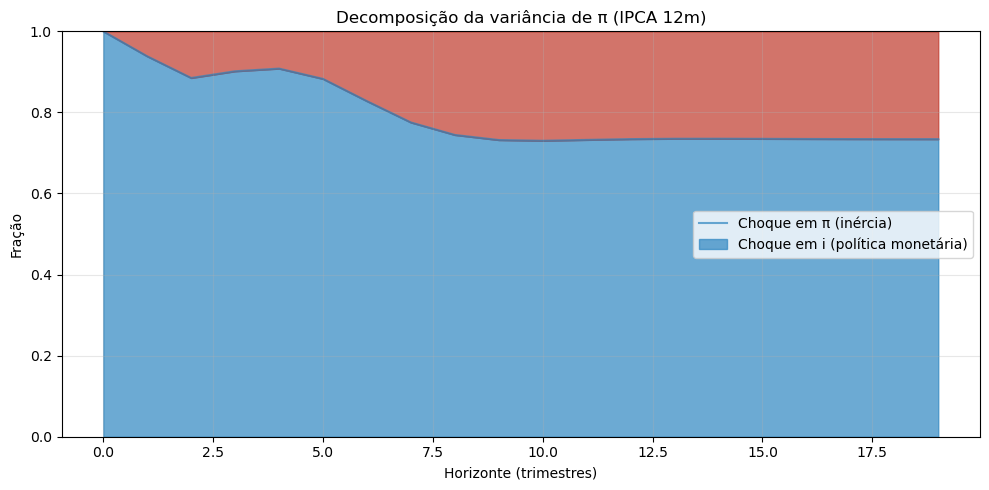

Figura salva em figs/fig_fevd_pi.png


In [7]:
fevd = var_res.fevd(20)
# decomp[i] = decomposição da variável i; aqui 0=π, 1=i
fevd_pi = fevd.decomp[0]
fevd_df = pd.DataFrame(fevd_pi, columns=["choque_pi", "choque_i"])
fevd_df.index.name = "Horizonte (tri)"

print("Decomposição da variância de π (fração explicada por cada choque):")
print(fevd_df.round(3).iloc[[0, 3, 7, 11, 15, 19]])
print()

frac_i_pi_lp = fevd_df["choque_i"].iloc[-1]
print(f"Em 20 trimestres, choques em i explicam {frac_i_pi_lp:.1%} da variância de π.")
if frac_i_pi_lp < 0.20:
    print("→ Política monetária explica POUCO da inflação brasileira — consistente com ALR.")
elif frac_i_pi_lp < 0.40:
    print("→ Política monetária explica parte MODERADA da inflação — posição intermediária.")
else:
    print("→ Política monetária explica MUITO da inflação — tese convencional sustenta.")

# Gráfico
fig, ax = plt.subplots(figsize=(10, 5))
fevd_df.plot.area(ax=ax, color=["#2E86C1", "#C0392B"], alpha=0.7)
ax.set_title("Decomposição da variância de π (IPCA 12m)")
ax.set_xlabel("Horizonte (trimestres)")
ax.set_ylabel("Fração")
ax.set_ylim(0, 1)
ax.legend(["Choque em π (inércia)", "Choque em i (política monetária)"], loc="center right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figs/fig_fevd_pi.png", dpi=120, bbox_inches="tight")
plt.show()
print("Figura salva em figs/fig_fevd_pi.png")


## 8. Veredito do Passo 1.2

In [8]:
print("=" * 70)
print("VEREDITO — PASSO 1.2 (Neutralidade da moeda)")
print("=" * 70)
print(f"  Lags escolhidos (AIC):                 {k_ar}")
print(f"  Rank de cointegração (Johansen):       {r_coint}")
if r_coint == 1:
    print(f"  β longo prazo VECM (π = β·i + c):      {beta_i_lp:+.3f}")
print(f"  Granger i → π (menor p-valor):         {p_min_i_pi:.3f}")
print(f"  Granger π → i (menor p-valor):         {p_min_pi_i:.3f}")
print(f"  Resposta de π a choque em i (20 tri):  {irf_df['pi'].iloc[-1]:+.3f}")
print(f"  Resposta de r a choque em i (20 tri):  {irf_df['r_implicito'].iloc[-1]:+.3f}")
print(f"  % variância de π por choques em i:     {frac_i_pi_lp:.1%}")
print()
print("-" * 70)

# Checklist
checks = []

# Neutralidade: r deve retornar ao neutro após choque em i
r_lp = irf_df["r_implicito"].iloc[-1]
if abs(r_lp) < 0.3:
    checks.append(("✓", "r retorna ao neutro após choque em i (neutralidade OK)"))
else:
    checks.append(("✗", f"r varia {r_lp:+.3f} após choque em i (neutralidade FALHA — r depende de i)"))

# Direção neofisheriana: π deve subir com choque em i (não cair)
pi_lp = irf_df["pi"].iloc[-1]
if pi_lp > 0:
    checks.append(("✓", f"π sobe {pi_lp:+.3f} após choque em i (direção ALR)"))
else:
    checks.append(("✗", f"π cai {pi_lp:+.3f} após choque em i (direção convencional)"))

# Granger: se SÓ π → i (BC reage) e NÃO i → π (Selic não move inflação) → reforça ALR
if p_min_pi_i < 0.05 and p_min_i_pi >= 0.05:
    checks.append(("✓", "BC reage à inflação mas Selic não causa inflação (consistente com ALR)"))
elif p_min_i_pi < 0.05:
    checks.append(("✗", "Selic Granger-causa inflação (mecanismo clássico vale)"))
else:
    checks.append(("~", "Sem Granger-causalidade em nenhuma direção"))

# Importância da PM: se explica POUCO da variância de π → canal fraco → consistente com ALR
if frac_i_pi_lp < 0.20:
    checks.append(("✓", f"Política monetária explica pouco da inflação ({frac_i_pi_lp:.1%}) — canal fraco"))
else:
    checks.append(("✗", f"Política monetária explica {frac_i_pi_lp:.1%} da inflação — canal forte"))

print("Checklist de compatibilidade com tese ALR:")
for sinal, texto in checks:
    print(f"  {sinal}  {texto}")

n_ok = sum(1 for s, _ in checks if s == "✓")
print()
print(f"Pontuação: {n_ok}/{len(checks)} testes compatíveis com tese ALR")
print()
if n_ok >= 3:
    print("LEITURA: A proposta do ALR tem BASE EMPÍRICA SIGNIFICATIVA.")
    print("         Vários testes convergem: política monetária é fraca, BC reage sem causar.")
elif n_ok == 2:
    print("LEITURA: Evidência MISTA para a tese do ALR.")
    print("         Partes do argumento sustentam, outras não.")
else:
    print("LEITURA: A tese do ALR encontra pouco respaldo nestes testes.")
    print("         A dinâmica dos dados é mais compatível com a visão convencional.")


VEREDITO — PASSO 1.2 (Neutralidade da moeda)
  Lags escolhidos (AIC):                 4
  Rank de cointegração (Johansen):       2
  Granger i → π (menor p-valor):         0.000
  Granger π → i (menor p-valor):         0.001
  Resposta de π a choque em i (20 tri):  +0.016
  Resposta de r a choque em i (20 tri):  +0.131
  % variância de π por choques em i:     26.6%

----------------------------------------------------------------------
Checklist de compatibilidade com tese ALR:
  ✓  r retorna ao neutro após choque em i (neutralidade OK)
  ✓  π sobe +0.016 após choque em i (direção ALR)
  ✗  Selic Granger-causa inflação (mecanismo clássico vale)
  ✗  Política monetária explica 26.6% da inflação — canal forte

Pontuação: 2/4 testes compatíveis com tese ALR

LEITURA: Evidência MISTA para a tese do ALR.
         Partes do argumento sustentam, outras não.
